# Custom simulations with SimpCalc

[`SimpCalc`][simpyson.calculator.SimpCalc] builds a SIMPSON input file from a spin system, a pulse sequence and a set of simulation parameters, and can run it for you. Use it when [`simulate_spectrum()`][simpyson.calculator.simulate_spectrum] is not enough: a pulse sequence, cross polarisation, or your own Tcl.

!!! note "Requires SIMPSON"
    Cells that call `.run()` need the `simpson` command on your `PATH` (see [Installation](../installation/install.md#when-do-you-need-simpson)). The outputs shown on this page were produced with SIMPSON 6.1.4 and are not re-computed when the documentation is built. Building and printing an input file never needs SIMPSON.

## The short version

A spin system, a pulse sequence name and the simulation parameters. `.print()` shows the SIMPSON input that was generated, `.run()` runs it and returns a [`Simpy`][simpyson.simpy.Simpy] object.

In [1]:
from __future__ import annotations

import matplotlib.pyplot as plt
import numpy as np

from simpyson import SimpCalc

spinsys = """
channels 13C
nuclei 13C 13C
shift 1 50p 0 0 0 0 0
shift 2 20p 0 0 0 0 0
"""

calc = SimpCalc(
    spinsys,
    pulse_sequence="pulse_90",
    proton_frequency=400e6,  # Hz
    spin_rate=10e3,  # Hz
    start_operator="Inz",
    detect_operator="Inp",
    method="direct",
    crystal_file="rep100",
    gamma_angles=10,
    np=4096,
    sw=20e3,  # Hz
    verbose=0,
    lb=10,
    zerofill=4096,
)
calc.print()

spinsys {
channels 13C
nuclei 13C 13C
shift 1 50p 0 0 0 0 0
shift 2 20p 0 0 0 0 0
}

par {
   crystal_file         rep100
   detect_operator      Inp
   gamma_angles         10
   method               direct
   np                   4096
   proton_frequency     400000000.0
   spin_rate            10000.0
   start_operator       Inz
   sw                   20000.0
   verbose              0
   variable num_channels    1
   variable pH              5.0
   variable phH             90
   variable plH             50000
   variable tsw             1e6/sw
}


proc pulseq {} {
    global par
    pulse $par(pH) $par(plH) $par(phH)
    acq_block {
        delay $par(tsw)
    }
}


proc main {} {
    global par
    set f [fsimpson]
    faddlb $f 10 0
    fzerofill $f 4096
    fft $f
    fsave $f $par(name).spe
}



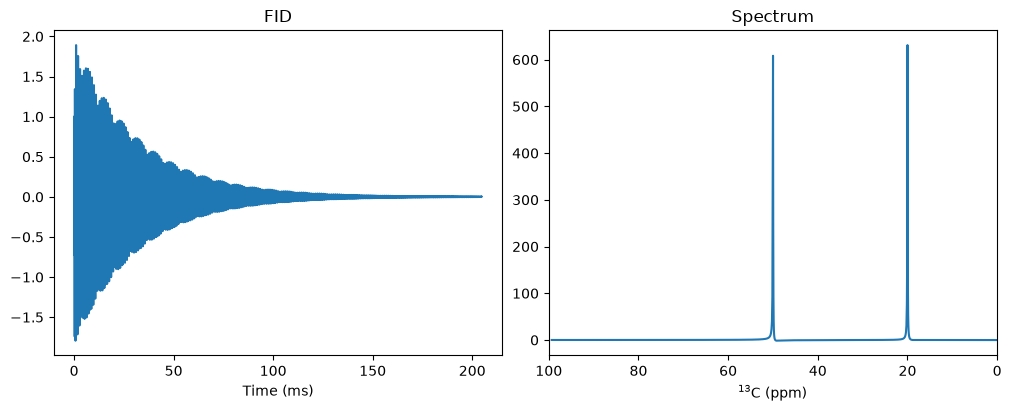

In [ ]:
result = calc.run()

fig, ax = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
ax[0].plot(result.fid["time"], result.fid["real"])
ax[0].set_xlabel("Time (ms)")
ax[0].set_title("FID")
ax[1].plot(result.spe["ppm"], result.spe["real"])
ax[1].set_xlim(100, 0)
ax[1].set_xlabel("$^{13}$C (ppm)")
ax[1].set_title("Spectrum")
plt.show()

## What `SimpCalc` needs

`SimpCalc` has no defaults for the simulation parameters. It raises a `ValueError` listing any that are missing when the input is generated.

| Parameter | Unit / values | Meaning |
|---|---|---|
| `proton_frequency` | Hz (e.g. `400e6`) | <sup>1</sup>H Larmor frequency; sets the field. Pass a number, not `'400MHz'`, the value is written to SIMPSON unchanged. |
| `spin_rate` | Hz | MAS rate (`0` for static). |
| `start_operator` | e.g. `Inz`, `Inx`, `I1x` | Starting density matrix. |
| `detect_operator` | e.g. `Inp`, `Inc`, `I2p+I3p` | Detected operator. |
| `np` | points | Number of acquisition points. |
| `sw` | Hz | Spectral width. |
| `method` | e.g. `direct`, `dsyev` | SIMPSON propagation method. |
| `crystal_file` | e.g. `rep100`, `rep2000` | Powder average. |
| `gamma_angles` | integer | Number of $\gamma$ angles. |
| `verbose` | integer or bit string | SIMPSON verbosity (`0` is quiet). |

Optional output settings:

| Parameter | Default | Meaning |
|---|---|---|
| `out_name` | temporary name | Output file name without extension. |
| `out_format` | `'spe'` | `'spe'`, `'fid'` or `'xreim'`. |
| `lb` | `20` | Exponential line broadening in Hz. |
| `gauss_lb` | `0` | Gaussian line broadening in Hz (skipped if `0`). |
| `zerofill` | `np` | Zero-filled size; equal to `np` means no zero-filling, use e.g. `2*np` to interpolate. |

Other keyword arguments are written into the `par` block as they are, so you can add SIMPSON parameters or your own. Parameters whose names start with `variable_` are written as `variable` entries.

What you can do with the calculator:

| Call | Result |
|---|---|
| `calc.print()` / `str(calc)` | Show the complete input file. |
| `calc.save("name.in")` | Write the input file to disk, e.g. to run it on a cluster. |
| `calc.run()` | Run SIMPSON and return a `Simpy` object. Temporary input and output files are deleted afterwards. |
| `calc.run(filepath="name.in", delete_files=False)` | Keep the input and output files. |
| `calc.run(read_output=False, delete_files=False)` | Return SIMPSON's printed output instead of a `Simpy` object. With the default `delete_files=True` the output file is deleted, so there would be nothing left. |
| `calc.run(dry_run=True)` | Write the input file and return the command, without running it. The file is kept. |
| `calc.run(simpson_path="/path/to/simpson")` | Use a SIMPSON executable that is not on your `PATH`. |

If SIMPSON fails, `run` raises a `RuntimeError` that contains SIMPSON's error message.

## Built-in templates

Pass a template name as `pulse_sequence`. There are three:

In [3]:
from simpyson.templates import pulseq_templates

for name, template in pulseq_templates.items():
    instance = template()
    print(f"{name}: {instance.description}")
    for parameter, value in instance.get_default_parameters().items():
        print(f"    {parameter.removeprefix('variable_'):<14} {value!r}")

no_pulse: No pulse, direct acquisition
    tsw            '1e6/sw'
    offset         0.0
    num_channels   1
pulse_90: Single 90° pulse on 1H
    pH             5.0
    plH            50000
    phH            '90'
    tsw            '1e6/sw'
    num_channels   1
cp_mas: Cross-polarization magic angle spinning
    pcp            1000
    plHcp          70000
    phHcp          '0'
    plCcp          69000
    phCcp          '0'
    dw             '1e6/spin_rate/gamma_angles'


| Template | What it does | Notes |
|---|---|---|
| `'no_pulse'` | Acquire only. | Start from a transverse operator (`Inx`). `offset` sets the carrier in Hz (`simulate_spectrum` uses this template). |
| `'pulse_90'` | One pulse on the **first channel**, then acquire. | Defaults: 5 µs at 50 kHz (a 90° pulse), phase 90. Other channels get zero power. Start from `Inz`. |
| `'cp_mas'` | Cross-polarisation contact pulse, then acquisition with the dipolar and J couplings turned off. | Needs `channels 1H 13C` in that order. Start from `I1x`. `pcp` is in µs, `plHcp`/`plCcp` are rf powers in Hz. |

All durations are in microseconds and all rf powers in Hz. The default `tsw` and `dw` are Tcl expressions evaluated by SIMPSON from `sw`, `spin_rate` and `gamma_angles`.

!!! warning "A misspelled template name is not an error"
    Any string that is not a template name is treated as your own Tcl code. `pulse_sequence="pulse90"` does not raise; it produces an input file with the text `pulse90` inside the pulse sequence. Use `calc.print()` to check what was generated.

## Adjusting template parameters

Pass the parameter by name, **without a prefix**, next to the other `SimpCalc` arguments. Here the pulse length of `pulse_90` is halved:

In [4]:
half = SimpCalc(
    spinsys,
    pulse_sequence="pulse_90",
    pH=2.5,  # pulse length in microseconds (default 5.0)
    proton_frequency=400e6,
    spin_rate=10e3,
    start_operator="Inz",
    detect_operator="Inp",
    method="direct",
    crystal_file="rep100",
    gamma_angles=10,
    np=4096,
    sw=20e3,
    verbose=0,
)
print([line.strip() for line in half.generate_par().splitlines() if "variable" in line])

['variable num_channels    1', 'variable pH              2.5', 'variable phH             90', 'variable plH             50000', 'variable tsw             1e6/sw']


There are two other ways, which give the same result:

- Build the template yourself and pass the object: `SimpCalc(spinsys, pulse_sequence=Pulse90(pH=2.5), ...)`. This is fine for single-channel spin systems; with several channels, use the name instead, because only the name route tells the template how many channels there are (otherwise SIMPSON stops with `pulse: arguments must match number of channels`).
- Change a template that is already attached to a calculator with `calc.pulse_sequence.update_parameters(pH=2.5)`. This is handy for scanning a parameter, see below.

Internally, template parameters are stored with a `variable_` prefix, which is how they appear in the `par` block (`variable pH 2.5`). Always give them without the prefix: `variable_pH=2.5` passed to `SimpCalc` together with a template *name* is ignored and the default is kept.

### Example: the effect of the contact time in CP

In cross polarisation, magnetisation moves from an abundant nucleus (I) to a dilute one (S) through their **dipolar coupling**. The coupling between spins I and S depends on their distance $r$:

$$b_{IS} = -\frac{\mu_0 \gamma_I \gamma_S \hbar}{4\pi r^3}$$

It falls off as $1/r^3$, so nearby atoms couple strongly. The spin system below has one <sup>1</sup>H coupled to two <sup>13</sup>C with different couplings:

<table style="margin-left: auto; margin-right: auto;">
  <tr><th>Pair</th><th><i>b</i><sub>IS</sub> (Hz)</th><th>Relative distance</th></tr>
  <tr><td>H-C<sub>2</sub></td><td>-10 000</td><td>closer</td></tr>
  <tr><td>H-C<sub>3</sub></td><td>-5 000</td><td>further</td></tr>
</table>

A **short contact time** transfers magnetisation only to the strongly coupled carbon; a **longer contact time** also reaches the weakly coupled one.

In [5]:
cp_spinsys = """
channels 1H 13C
nuclei 1H 13C 13C
shift 1 2.0p 0 0 0 0 0
shift 2 10p 0 0 0 0 0
shift 3 15p 0 0 0 0 0
dipole 1 2 -10000 0 0 0
dipole 1 3 -5000 0 0 0
"""

cp_calc = SimpCalc(
    cp_spinsys,
    pulse_sequence="cp_mas",
    proton_frequency=400e6,
    sw=20e3,
    spin_rate=10e3,
    start_operator="I1x",
    detect_operator="I2p+I3p",
    method="direct",
    crystal_file="rep100",
    gamma_angles=10,
    verbose=0,
    np=4096,
    lb=20,
)

cp_calc.pulse_sequence.update_parameters(pcp=1000)  # 1 ms contact time
sim_short = cp_calc.run()

cp_calc.pulse_sequence.update_parameters(pcp=8000)  # 8 ms contact time
sim_long = cp_calc.run()

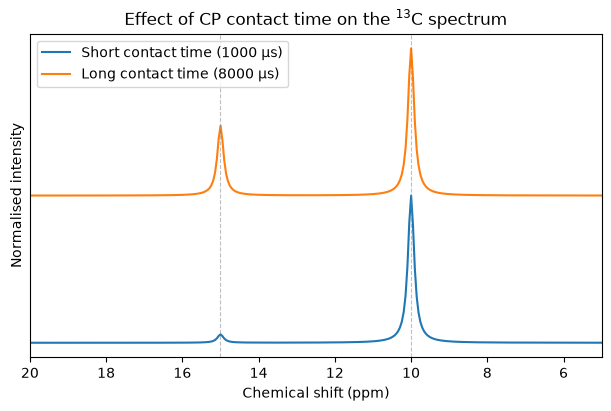

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)

ax.plot(
    sim_short.spe["ppm"],
    sim_short.spe["real"] / sim_short.spe["real"].max(),
    label="Short contact time (1000 µs)",
)
ax.plot(
    sim_long.spe["ppm"],
    sim_long.spe["real"] / sim_long.spe["real"].max() + 1,
    label="Long contact time (8000 µs)",
)
ax.axvline(10, color="gray", linestyle="--", linewidth=0.8, alpha=0.5)
ax.axvline(15, color="gray", linestyle="--", linewidth=0.8, alpha=0.5)
ax.set_xlabel("Chemical shift (ppm)")
ax.set_ylabel("Normalised intensity")
ax.set_xlim(20, 5)
ax.set_yticks([])
ax.legend()
ax.set_title("Effect of CP contact time on the $^{13}$C spectrum")
plt.show()

## Custom pulse sequences

For anything the templates do not cover, pass your own SIMPSON Tcl as `pulse_sequence`. The Tcl is the **body** of the pulse sequence: you write the SIMPSON commands, and `SimpCalc` wraps them in

```tcl
proc pulseq {} {
    global par
    ...your code...
}
```

Parameters you want to vary go in the code as `$par(name)` placeholders. Give each one a value as a keyword argument; `SimpCalc` writes it into the `par` block as `variable name value`. Here a single pulse of length `pw` (µs) and power `rf` (Hz), followed by acquisition:

In [7]:
tcl = """
pulse $par(pw) $par(rf) 90
acq_block {
    delay $par(tsw)
}
"""

pulse_spinsys = "channels 13C\nnuclei 13C\nshift 1 20p 0 0 0 0 0\n"

custom = SimpCalc(
    pulse_spinsys,
    pulse_sequence=tcl,
    pw=2.5,
    rf=100e3,
    tsw="1e6/sw",  # values for the $par(...) placeholders
    proton_frequency=400e6,
    spin_rate=10e3,
    start_operator="Inz",
    detect_operator="Inp",
    method="direct",
    crystal_file="rep100",
    gamma_angles=10,
    np=1024,
    sw=20e3,
    verbose=0,
)
custom.print()

spinsys {
channels 13C
nuclei 13C
shift 1 20p 0 0 0 0 0
}

par {
   crystal_file         rep100
   detect_operator      Inp
   gamma_angles         10
   method               direct
   np                   1024
   proton_frequency     400000000.0
   spin_rate            10000.0
   start_operator       Inz
   sw                   20000.0
   verbose              0
   variable pw              2.5
   variable rf              100000.0
   variable tsw             1e6/sw
}


proc pulseq {} {
    global par

pulse $par(pw) $par(rf) 90
acq_block {
    delay $par(tsw)
}

}


proc main {} {
    global par
    set f [fsimpson]
    faddlb $f 20 0
    fzerofill $f 1024
    fft $f
    fsave $f $par(name).spe
}



How the placeholders are handled:

- Every `$par(name)` in the code needs a value. If one is missing, `SimpCalc` raises `ValueError: Missing required parameters: ...` straight away.
- Names that are standard `SimpCalc` parameters (`spin_rate`, `sw`, `np`, ...) can be used as `$par(spin_rate)` without being repeated.
- A keyword argument that matches no `$par(...)` is not passed to the pulse sequence. It is still written into the `par` block as a plain entry, so a typo does not raise an error either.
- Values can be numbers or Tcl expressions given as strings (`tsw="1e6/sw"`). The `variable` lines are written in alphabetical order, so an expression can only refer to a variable that sorts **before** it.
- If your code starts with `proc pulseq`, it is used as it is and nothing is added. This lets you define helper procedures (see below).

Change a value between runs with `update_parameters`. For example, a nutation curve: the signal after one pulse against the pulse length.

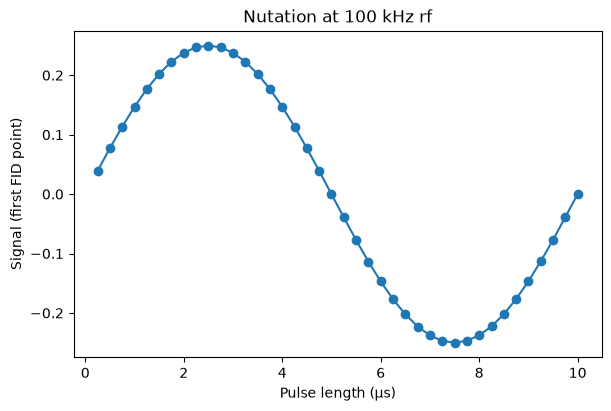

In [8]:
pulse_lengths = np.linspace(0.25, 10, 40)  # microseconds
signal = []
for pw in pulse_lengths:
    custom.pulse_sequence.update_parameters(pw=float(pw))
    signal.append(custom.run().fid["real"][0])

fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
ax.plot(pulse_lengths, signal, "o-")
ax.set_xlabel("Pulse length (µs)")
ax.set_ylabel("Signal (first FID point)")
ax.set_title("Nutation at 100 kHz rf")
plt.show()

The signal is maximal at 2.5 µs, a 90° pulse at 100 kHz ($1/(4\,\nu_1)$), and zero at 5 µs (180°).

### Ramped versus flat contact

Many pulse sequences already exist online as SIMPSON input files. The example below is taken from [dnp-grenoble/simpson](https://github.com/dnp-grenoble/simpson) repository that contains several experiments for recoupling, decoupling, cross polarisation and more. 

To use one, copy its `pulseq` procedure and any helper procedures into a string, replace fixed numbers by `$par(...)` placeholders, and give the values as keyword arguments.

The example below is adapted from its ramped cross-polarisation (`cross_polarisation/rampcp.in`): the proton power is ramped from `ramp_start` to `ramp_stop` percent during the contact. Because the code starts with `proc pulseq`, the helper procedure `ramp` can be defined next to it.

A flat contact only transfers well when the rf powers match a Hartmann-Hahn condition, $\nu_1^{\mathrm{H}} - \nu_1^{\mathrm{C}} = \pm n\,\nu_\mathrm{r}$. Here $|60 - 70| = 10$ kHz is equal to the spin rate, so $n = 1$. A ramp sweeps the proton power through the condition, so it also works when the nominal power is off, as long as the match lies inside the swept range.

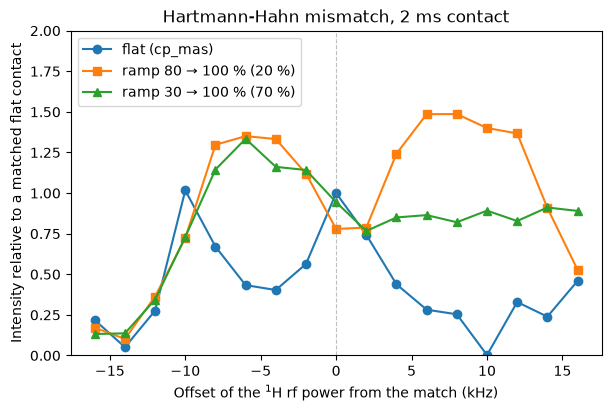

In [ ]:
ramped_cp = """
proc pulseq {} {
    global par
    set tr [expr 1e6/$par(spin_rate)]
    set ntr [expr round($par(tcp)/$tr)]
    set tau [expr $ntr*$tr]
    ramp $tau $par(ramp_start) $par(ramp_stop) $par(steps) $par(rf_H) $par(rf_C)
    acq_block {
        delay $par(dw)
    }
}

proc ramp {tau start stop steps rfH rfC} {
    set dt [expr $tau/$steps]
    for {set i 1} {$i <= $steps} {incr i} {
        set per_amp [expr $start+($i*($stop-$start)/$steps)]
        set amp [expr $rfH*$per_amp/100]
        pulse $dt $amp 0 $rfC 0
    }
}
"""

offsets = np.arange(
    -16, 17, 2
)  # change of the 1H power (kHz) around the n = 1 match, 60 kHz


def intensity(result):
    """Summed intensity of the 10 ppm carbon (the strongly coupled one)."""
    ppm, real = result.spe["ppm"], result.spe["real"]
    return real[np.abs(ppm - 10) < 3].sum()


def run_flat(rf_H):
    cp_calc.pulse_sequence.update_parameters(pcp=2000, plHcp=rf_H, plCcp=70e3)
    return intensity(cp_calc.run())


def run_ramp(rf_H, start):
    ramp_calc = SimpCalc(
        cp_spinsys,
        pulse_sequence=ramped_cp,
        tcp=2000,
        ramp_start=start,
        ramp_stop=100,
        steps=20,
        rf_H=rf_H,
        rf_C=70e3,
        dw="1e6/spin_rate/gamma_angles",
        proton_frequency=400e6,
        spin_rate=10e3,
        start_operator="I1x",
        detect_operator="I2p+I3p",
        method="direct",
        crystal_file="rep100",
        gamma_angles=10,
        np=4096,
        sw=20e3,
        verbose=0,
        lb=20,
    )
    return intensity(ramp_calc.run())


flat = np.array([run_flat(60e3 + d * 1e3) for d in offsets])
ramp_20 = np.array([run_ramp(60e3 + d * 1e3, 80) for d in offsets])
ramp_70 = np.array([run_ramp(60e3 + d * 1e3, 30) for d in offsets])

best = flat[offsets == 0][0]  # flat contact exactly on the match
fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
ax.plot(offsets, flat / best, "o-", label="flat (cp_mas)")
ax.plot(offsets, ramp_20 / best, "s-", label="ramp 80 → 100 % (20 %)")
ax.plot(offsets, ramp_70 / best, "^-", label="ramp 30 → 100 % (70 %)")
ax.axvline(0, color="gray", linestyle="--", linewidth=0.8, alpha=0.5)
ax.set_xlabel("Offset of the $^1$H rf power from the match (kHz)")
ax.set_ylabel("Intensity relative to a matched flat contact")
ax.set_title("Hartmann-Hahn mismatch, 2 ms contact")
ax.set_ylim(0, 2.0)
ax.legend(loc="upper left")
plt.show()

The flat contact is best right on a match, at 0 kHz, and at −10 kHz, where the proton power of 50 kHz is the $n = 2$ condition. A few kHz away it falls to a fraction of that, and at +10 kHz, where both channels have the same power, it transfers nothing. The 20 % ramp gives less than the flat contact at 0 kHz, because the match lies at the very end of its sweep. Whenever the match lies inside its range (−8 to −4 kHz and +4 to +12 kHz) it transfers 1.2 to 1.5 times as much as the matched flat contact. The 70 % ramp has a lower maximum, but gives 0.8 to 0.9 over a much wider range (+2 to +16 kHz) because it passes through the match faster.

## Writing your own template class

If you reuse a sequence often, subclass [`PulseSequenceTemplate`][simpyson.templates.PulseSequenceTemplate]. You give it default parameters (with the `variable_` prefix), the set of required parameters, and the Tcl. The base class checks that all required parameters are present. Pass an instance to `SimpCalc`:

In [ ]:
from simpyson.templates import PulseSequenceTemplate


class HahnEcho(PulseSequenceTemplate):
    """90 - tau - 180 - tau - acquire on the first channel."""

    def get_default_parameters(self):
        return {
            "variable_pw": 2.5,
            "variable_rf": 100e3,
            "variable_tau": 100,
            "variable_tsw": "1e6/sw",
        }

    def get_required_parameters(self):
        return {"variable_pw", "variable_rf", "variable_tau", "variable_tsw"}

    def generate_code(self):
        return """
proc pulseq {} {
    global par
    pulse $par(pw) $par(rf) 90
    delay $par(tau)
    pulse [expr 2*$par(pw)] $par(rf) 0
    delay $par(tau)
    acq_block {
        delay $par(tsw)
    }
}
"""


echo = SimpCalc(
    pulse_spinsys,
    pulse_sequence=HahnEcho(tau=50),  # microseconds
    proton_frequency=400e6,
    spin_rate=10e3,
    start_operator="Inz",
    detect_operator="Inp",
    method="direct",
    crystal_file="rep100",
    gamma_angles=10,
    np=1024,
    sw=20e3,
    verbose=0,
).run()
print(
    f"Peak of the echo spectrum: {echo.spe['ppm'][echo.spe['real'].argmax()]:.1f} ppm"
)

Peak of the echo spectrum: 20.0 ppm


SIMPSON itself is the authority on what a pulse sequence may contain; see the [SIMPSON papers](https://doi.org/10.1016/j.jmr.2011.09.008) and the [dnp-grenoble/simpson](https://github.com/dnp-grenoble/simpson) examples for the available commands.